### Cluster Analysis

#### Keith R. Holdaway FGS

#### We are going to generate synthetic well log data for a petrophysicist.
The typical logs we might generate are: Gamma Ray (GR), Resistivity (RT), Neutron Porosity (NPHI), and Bulk Density (RHOB).
We will create two clusters representing two different rock types, for example, sand and shale.

Steps:

Generate synthetic well log data for two clusters (sand and shale) with some overlap.

Write the data to a CSV file.

Apply k-means and hierarchical clustering to the data.

Visualize the results in 2D and 3D plots to distinguish the two techniques.

Let's assume we have 100 depth points for simplicity.

For sand:
GR: lower values (say 20-50 API)
RT: higher values (say 100-200 ohm.m)
NPHI: higher porosity (0.15-0.25)
RHOB: lower density (2.0-2.4 g/cc)

For shale:
GR: higher values (70-100 API)
RT: lower values (10-30 ohm.m)
NPHI: lower porosity (0.05-0.15)
RHOB: higher density (2.4-2.8 g/cc)

### We'll generate 50 points for each cluster and then combine.

We'll then standardize the data because clustering algorithms are sensitive to the scale of the features.

For visualization, we can use PCA to reduce to 2D or 3D, but since we have 4 features, we can also plot pairs.

We'll show:

Scatter plot of the original data in 2D (using the first two principal components or two features) with true labels.

Scatter plot of k-means clustering results.

Dendrogram for hierarchical clustering.

Scatter plot of hierarchical clustering results (for the same number of clusters as k-means, i.e., 2).

Generating synthetic well log data...
Data saved to 'well_log_data.csv'
PCA explained variance ratio: [0.48768037 0.41716544]

Performing K-means clustering...
Performing Hierarchical clustering...


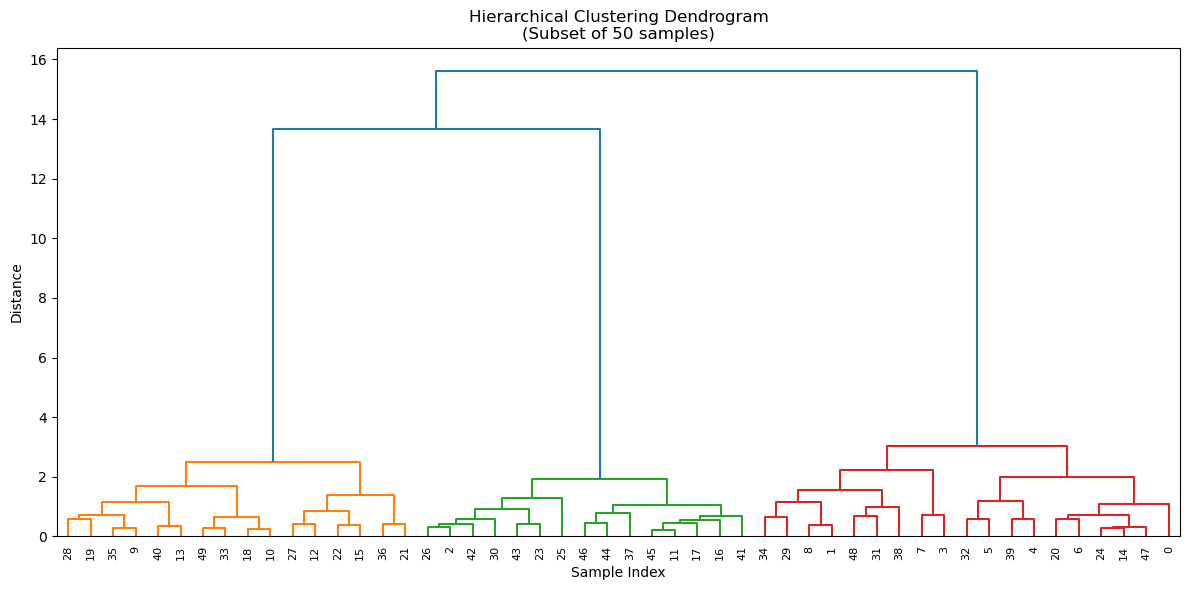


CLUSTER ANALYSIS RESULTS

--- Cluster 0 Statistics ---
K-means - GR: 30.0, NPHI: 0.250, RHOB: 2.35
Hierarchical - GR: 30.0, NPHI: 0.250, RHOB: 2.35
K-means facies distribution: Sandstone: 199, Shale: 0, Limestone: 0
Hierarchical facies distribution: Sandstone: 199, Shale: 0, Limestone: 0

--- Cluster 1 Statistics ---
K-means - GR: 117.1, NPHI: 0.150, RHOB: 2.50
Hierarchical - GR: 117.1, NPHI: 0.150, RHOB: 2.50
K-means facies distribution: Sandstone: 0, Shale: 151, Limestone: 0
Hierarchical facies distribution: Sandstone: 0, Shale: 151, Limestone: 0

--- Cluster 2 Statistics ---
K-means - GR: 42.4, NPHI: 0.080, RHOB: 2.70
Hierarchical - GR: 42.4, NPHI: 0.080, RHOB: 2.70
K-means facies distribution: Sandstone: 0, Shale: 0, Limestone: 150
Hierarchical facies distribution: Sandstone: 0, Shale: 0, Limestone: 150

Generating comprehensive visualization...


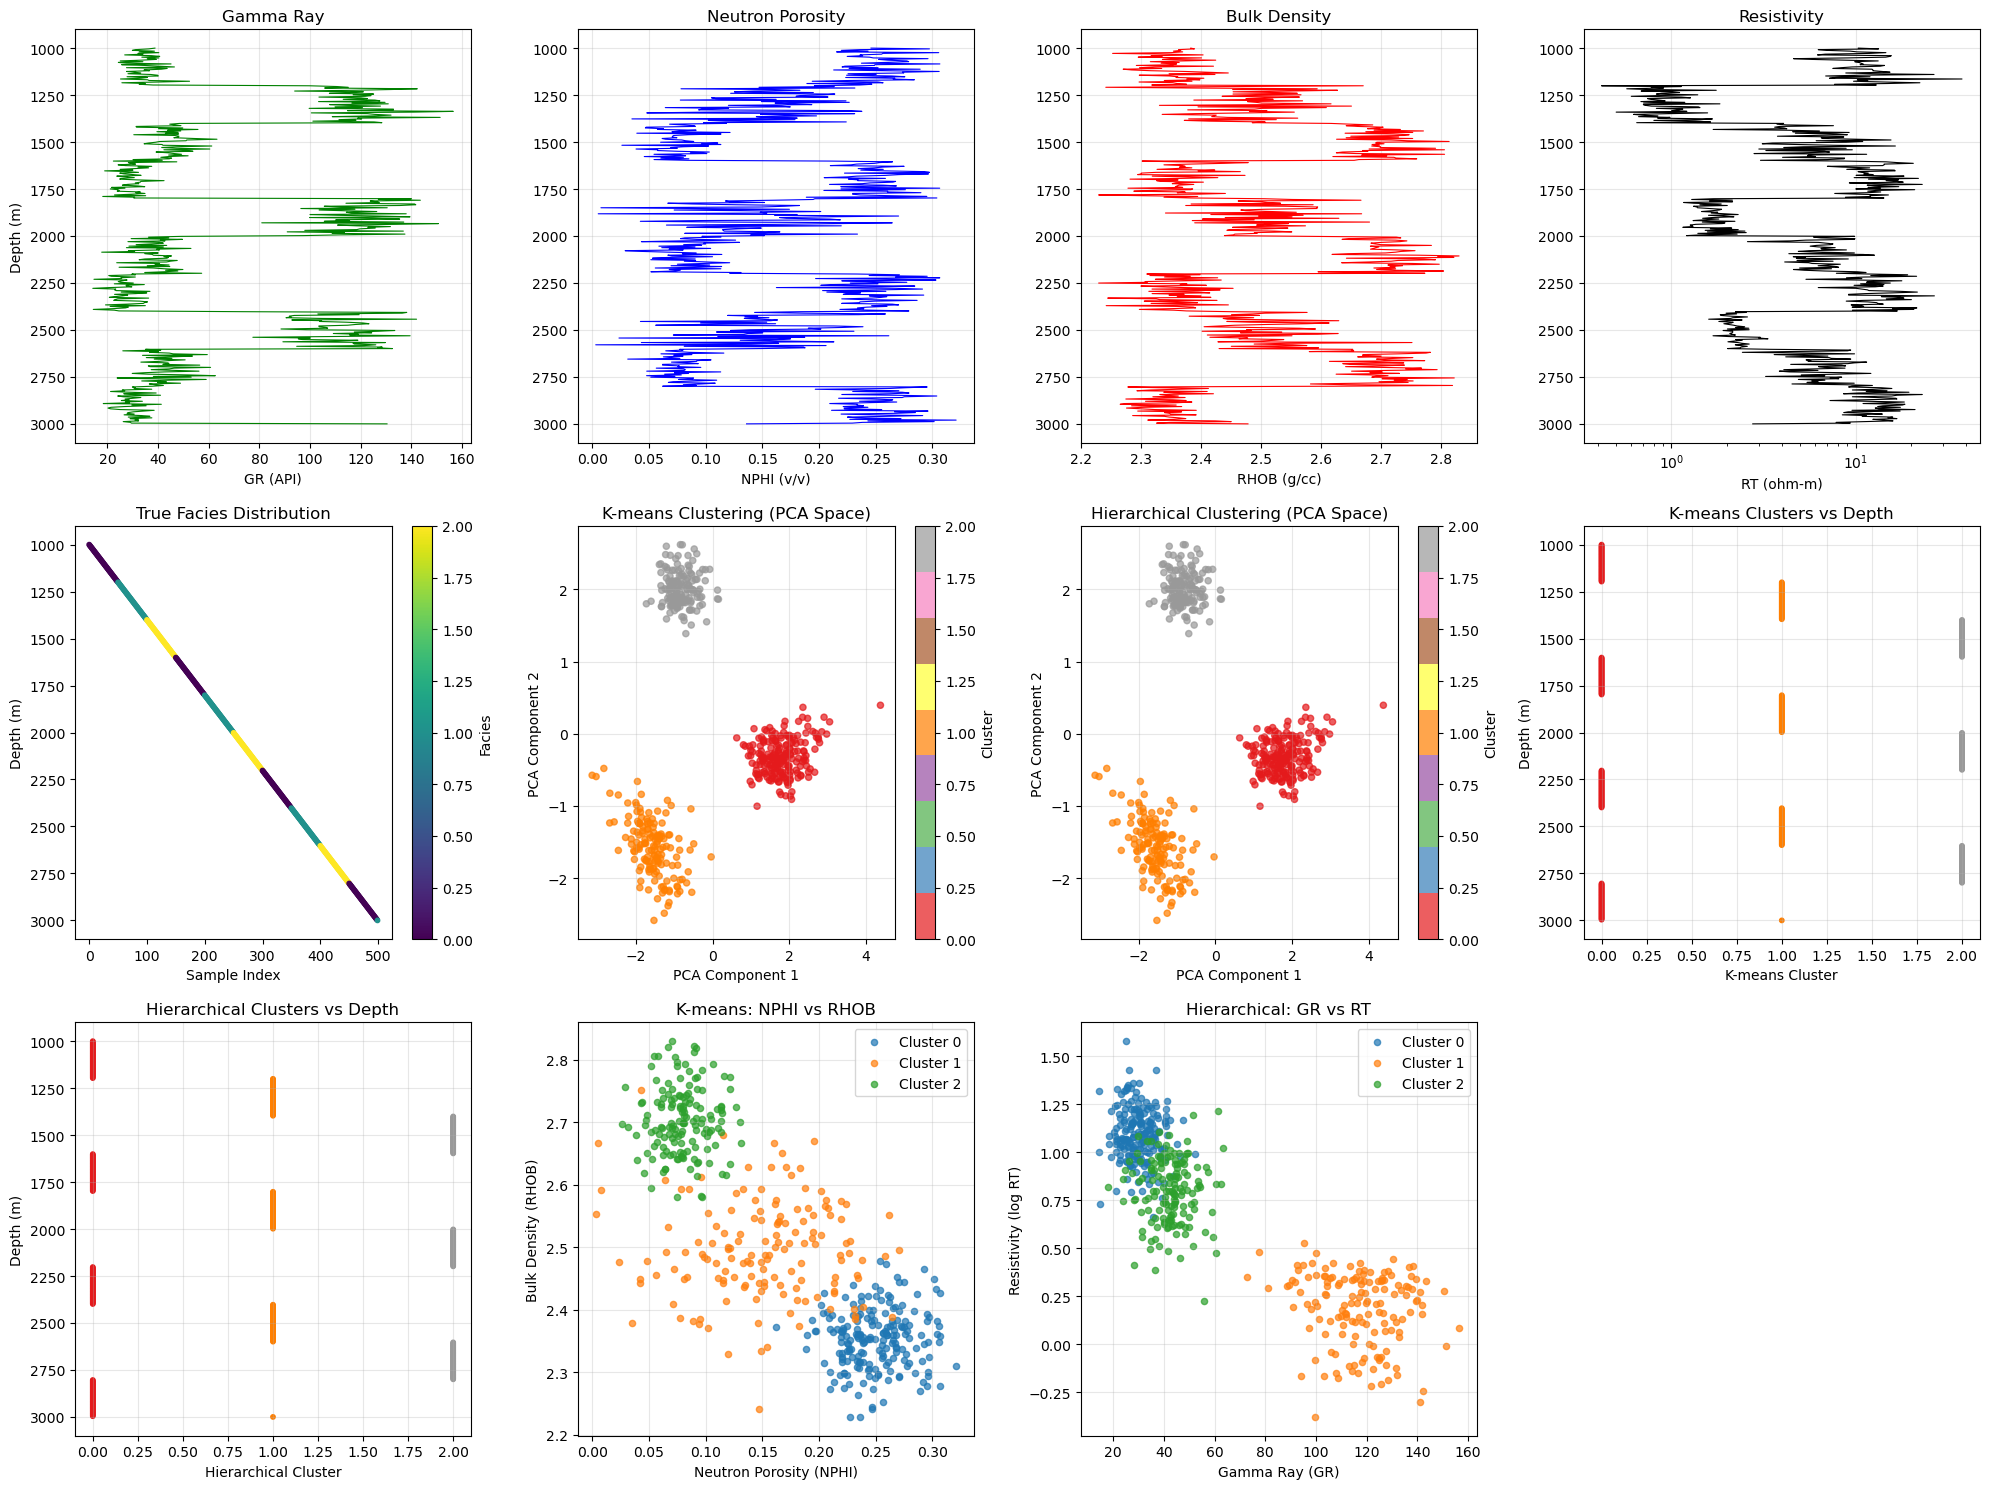


CLUSTER CENTROIDS COMPARISON

GR Centroids:
K-means:    ['-0.76', '1.45', '-0.45']
Hierarchical: ['-0.76', '1.45', '-0.45']

NPHI Centroids:
K-means:    ['1.01', '-0.23', '-1.10']
Hierarchical: ['1.01', '-0.23', '-1.10']

RHOB Centroids:
K-means:    ['-0.94', '-0.03', '1.29']
Hierarchical: ['-0.94', '-0.03', '1.29']

DT Centroids:
K-means:    ['-0.01', '1.28', '-1.27']
Hierarchical: ['-0.01', '1.28', '-1.27']

RT Centroids:
K-means:    ['0.93', '-1.06', '-0.17']
Hierarchical: ['0.93', '-1.06', '-0.17']

KEY INSIGHTS FOR PETROPHYSICISTS:
1. K-means:
   - Partitions data into spherical clusters of similar size
   - Sensitive to initial centroid placement
   - Works well when clusters are well-separated and spherical
   - Faster for large datasets

2. Hierarchical Clustering:
   - Creates a tree-like structure (dendrogram) of nested clusters
   - No need to specify number of clusters in advance
   - Can capture non-spherical clusters
   - More computationally intensive

3. Petrophysical 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic well log data for three lithofacies: Sandstone, Shale, Limestone
def generate_well_logs(n_points=500):
    """Generate synthetic well log data mimicking real petrophysical measurements"""
    
    # Create depth array
    depth = np.linspace(1000, 3000, n_points)
    
    # Initialize arrays for different logs
    gr = np.zeros(n_points)  # Gamma Ray
    nphi = np.zeros(n_points)  # Neutron Porosity
    rhob = np.zeros(n_points)  # Bulk Density
    dt = np.zeros(n_points)   # Sonic (Delta-T)
    rt = np.zeros(n_points)   # True Resistivity
    
    # Define characteristics for three lithofacies
    # Facies 0: Sandstone (clean, porous)
    # Facies 1: Shale (high GR, low resistivity)
    # Facies 2: Limestone (dense, low porosity)
    
    facies = np.zeros(n_points, dtype=int)
    
    for i in range(n_points):
        # Create alternating zones of different facies
        zone = int((depth[i] - 1000) / 200) % 3
        
        if zone == 0:  # Sandstone
            gr[i] = np.random.normal(30, 5)  # Low GR
            nphi[i] = np.random.normal(0.25, 0.03)  # High porosity
            rhob[i] = np.random.normal(2.35, 0.05)  # Moderate density
            dt[i] = np.random.normal(75, 3)  # Moderate sonic
            rt[i] = np.random.lognormal(2.5, 0.3)  # High resistivity
            facies[i] = 0
            
        elif zone == 1:  # Shale
            gr[i] = np.random.normal(120, 15)  # High GR
            nphi[i] = np.random.normal(0.15, 0.05)  # Moderate porosity
            rhob[i] = np.random.normal(2.5, 0.08)  # High density
            dt[i] = np.random.normal(100, 5)  # High sonic
            rt[i] = np.random.lognormal(0.5, 0.2)  # Low resistivity
            facies[i] = 1
            
        else:  # Limestone
            gr[i] = np.random.normal(45, 8)  # Moderate GR
            nphi[i] = np.random.normal(0.08, 0.02)  # Low porosity
            rhob[i] = np.random.normal(2.7, 0.06)  # High density
            dt[i] = np.random.normal(50, 2)  # Low sonic
            rt[i] = np.random.lognormal(1.8, 0.4)  # Moderate resistivity
            facies[i] = 2
    
    # Add some noise and trends to simulate real well data
    gr += 5 * np.sin(depth / 500) + np.random.normal(0, 3, n_points)
    rt += 0.1 * (depth - 2000) / 100
    
    # Create DataFrame
    data = pd.DataFrame({
        'DEPTH': depth,
        'GR': gr,
        'NPHI': nphi,
        'RHOB': rhob,
        'DT': dt,
        'RT': rt,
        'FACIES': facies
    })
    
    return data

# Generate the well log data
print("Generating synthetic well log data...")
well_data = generate_well_logs(500)

# Save to CSV file
well_data.to_csv('well_log_data.csv', index=False)
print("Data saved to 'well_log_data.csv'")

# Prepare data for clustering (exclude depth and facies columns)
X = well_data[['GR', 'NPHI', 'RHOB', 'DT', 'RT']].values

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Add PCA results to dataframe
well_data['PCA1'] = X_pca[:, 0]
well_data['PCA2'] = X_pca[:, 1]

print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")

# Create visualization function
def plot_well_logs_with_clusters(data, kmeans_labels, hierarchical_labels, true_facies):
    """Create comprehensive visualization of clustering results"""
    
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Original well logs
    ax1 = plt.subplot(3, 4, 1)
    ax1.plot(data['GR'], data['DEPTH'], 'g-', linewidth=0.8)
    ax1.set_xlabel('GR (API)')
    ax1.set_ylabel('Depth (m)')
    ax1.set_title('Gamma Ray')
    ax1.invert_yaxis()
    ax1.grid(True, alpha=0.3)
    
    ax2 = plt.subplot(3, 4, 2)
    ax2.plot(data['NPHI'], data['DEPTH'], 'b-', linewidth=0.8)
    ax2.set_xlabel('NPHI (v/v)')
    ax2.set_title('Neutron Porosity')
    ax2.invert_yaxis()
    ax2.grid(True, alpha=0.3)
    
    ax3 = plt.subplot(3, 4, 3)
    ax3.plot(data['RHOB'], data['DEPTH'], 'r-', linewidth=0.8)
    ax3.set_xlabel('RHOB (g/cc)')
    ax3.set_title('Bulk Density')
    ax3.invert_yaxis()
    ax3.grid(True, alpha=0.3)
    
    ax4 = plt.subplot(3, 4, 4)
    ax4.semilogx(data['RT'], data['DEPTH'], 'k-', linewidth=0.8)
    ax4.set_xlabel('RT (ohm-m)')
    ax4.set_title('Resistivity')
    ax4.invert_yaxis()
    ax4.grid(True, alpha=0.3)
    
    # 2. True facies vs depth
    ax5 = plt.subplot(3, 4, 5)
    scatter5 = ax5.scatter(range(len(data)), data['DEPTH'], c=true_facies, 
                          cmap='viridis', s=10)
    ax5.set_xlabel('Sample Index')
    ax5.set_ylabel('Depth (m)')
    ax5.set_title('True Facies Distribution')
    ax5.invert_yaxis()
    plt.colorbar(scatter5, ax=ax5, label='Facies')
    
    # 3. K-means clustering results
    ax6 = plt.subplot(3, 4, 6)
    scatter6 = ax6.scatter(data['PCA1'], data['PCA2'], c=kmeans_labels, 
                          cmap='Set1', s=20, alpha=0.7)
    ax6.set_xlabel('PCA Component 1')
    ax6.set_ylabel('PCA Component 2')
    ax6.set_title('K-means Clustering (PCA Space)')
    ax6.grid(True, alpha=0.3)
    plt.colorbar(scatter6, ax=ax6, label='Cluster')
    
    # 4. Hierarchical clustering results
    ax7 = plt.subplot(3, 4, 7)
    scatter7 = ax7.scatter(data['PCA1'], data['PCA2'], c=hierarchical_labels, 
                          cmap='Set1', s=20, alpha=0.7)
    ax7.set_xlabel('PCA Component 1')
    ax7.set_ylabel('PCA Component 2')
    ax7.set_title('Hierarchical Clustering (PCA Space)')
    ax7.grid(True, alpha=0.3)
    plt.colorbar(scatter7, ax=ax7, label='Cluster')
    
    # 5. K-means vs Depth
    ax8 = plt.subplot(3, 4, 8)
    scatter8 = ax8.scatter(kmeans_labels, data['DEPTH'], c=kmeans_labels, 
                          cmap='Set1', s=10)
    ax8.set_xlabel('K-means Cluster')
    ax8.set_ylabel('Depth (m)')
    ax8.set_title('K-means Clusters vs Depth')
    ax8.invert_yaxis()
    ax8.grid(True, alpha=0.3)
    
    # 6. Hierarchical vs Depth
    ax9 = plt.subplot(3, 4, 9)
    scatter9 = ax9.scatter(hierarchical_labels, data['DEPTH'], c=hierarchical_labels, 
                          cmap='Set1', s=10)
    ax9.set_xlabel('Hierarchical Cluster')
    ax9.set_ylabel('Depth (m)')
    ax9.set_title('Hierarchical Clusters vs Depth')
    ax9.invert_yaxis()
    ax9.grid(True, alpha=0.3)
    
    # 7. Cross-plot: NPHI vs RHOB with clusters
    ax10 = plt.subplot(3, 4, 10)
    for cluster in np.unique(kmeans_labels):
        mask = kmeans_labels == cluster
        ax10.scatter(data['NPHI'][mask], data['RHOB'][mask], 
                    label=f'Cluster {cluster}', s=20, alpha=0.7)
    ax10.set_xlabel('Neutron Porosity (NPHI)')
    ax10.set_ylabel('Bulk Density (RHOB)')
    ax10.set_title('K-means: NPHI vs RHOB')
    ax10.legend()
    ax10.grid(True, alpha=0.3)
    
    # 8. Cross-plot: GR vs RT with clusters
    ax11 = plt.subplot(3, 4, 11)
    for cluster in np.unique(hierarchical_labels):
        mask = hierarchical_labels == cluster
        ax11.scatter(data['GR'][mask], np.log10(data['RT'][mask]), 
                    label=f'Cluster {cluster}', s=20, alpha=0.7)
    ax11.set_xlabel('Gamma Ray (GR)')
    ax11.set_ylabel('Resistivity (log RT)')
    ax11.set_title('Hierarchical: GR vs RT')
    ax11.legend()
    ax11.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Perform K-means clustering
print("\nPerforming K-means clustering...")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Perform Hierarchical clustering
print("Performing Hierarchical clustering...")
hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Create dendrogram for hierarchical clustering
plt.figure(figsize=(12, 6))
# Use a subset of data for clearer dendrogram
subset_indices = np.random.choice(len(X_scaled), size=50, replace=False)
X_subset = X_scaled[subset_indices]

linked = linkage(X_subset, method='ward')
dendrogram(linked, orientation='top', distance_sort='descending', 
           show_leaf_counts=True, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram\n(Subset of 50 samples)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

# Compare cluster statistics
def print_cluster_statistics(data, kmeans_labels, hierarchical_labels, true_facies):
    """Print statistical comparison of clustering results"""
    
    print("\n" + "="*60)
    print("CLUSTER ANALYSIS RESULTS")
    print("="*60)
    
    for i in range(3):
        print(f"\n--- Cluster {i} Statistics ---")
        
        # K-means
        kmeans_mask = kmeans_labels == i
        kmeans_gr = data['GR'][kmeans_mask].mean()
        kmeans_nphi = data['NPHI'][kmeans_mask].mean()
        kmeans_rhob = data['RHOB'][kmeans_mask].mean()
        
        # Hierarchical
        hierarchical_mask = hierarchical_labels == i
        hierarchical_gr = data['GR'][hierarchical_mask].mean()
        hierarchical_nphi = data['NPHI'][hierarchical_mask].mean()
        hierarchical_rhob = data['RHOB'][hierarchical_mask].mean()
        
        # True facies distribution in clusters
        kmeans_facies_dist = [np.sum(true_facies[kmeans_mask] == j) for j in range(3)]
        hierarchical_facies_dist = [np.sum(true_facies[hierarchical_mask] == j) for j in range(3)]
        
        print(f"K-means - GR: {kmeans_gr:.1f}, NPHI: {kmeans_nphi:.3f}, RHOB: {kmeans_rhob:.2f}")
        print(f"Hierarchical - GR: {hierarchical_gr:.1f}, NPHI: {hierarchical_nphi:.3f}, RHOB: {hierarchical_rhob:.2f}")
        print(f"K-means facies distribution: Sandstone: {kmeans_facies_dist[0]}, "
              f"Shale: {kmeans_facies_dist[1]}, Limestone: {kmeans_facies_dist[2]}")
        print(f"Hierarchical facies distribution: Sandstone: {hierarchical_facies_dist[0]}, "
              f"Shale: {hierarchical_facies_dist[1]}, Limestone: {hierarchical_facies_dist[2]}")

# Print statistics
print_cluster_statistics(well_data, kmeans_labels, hierarchical_labels, well_data['FACIES'].values)

# Create main visualization
print("\nGenerating comprehensive visualization...")
plot_well_logs_with_clusters(well_data, kmeans_labels, hierarchical_labels, well_data['FACIES'].values)

# Additional comparison: Cluster centroids
print("\n" + "="*60)
print("CLUSTER CENTROIDS COMPARISON")
print("="*60)

features = ['GR', 'NPHI', 'RHOB', 'DT', 'RT']
for i, feature in enumerate(features):
    print(f"\n{feature} Centroids:")
    print(f"K-means:    {[f'{x:.2f}' for x in kmeans.cluster_centers_[:, i]]}")
    
    # Calculate hierarchical centroids manually
    hierarchical_centroids = []
    for cluster in range(3):
        mask = hierarchical_labels == cluster
        centroid = X_scaled[mask, i].mean()
        hierarchical_centroids.append(centroid)
    print(f"Hierarchical: {[f'{x:.2f}' for x in hierarchical_centroids]}")

print("\n" + "="*60)
print("KEY INSIGHTS FOR PETROPHYSICISTS:")
print("="*60)
print("1. K-means:")
print("   - Partitions data into spherical clusters of similar size")
print("   - Sensitive to initial centroid placement")
print("   - Works well when clusters are well-separated and spherical")
print("   - Faster for large datasets")
print("\n2. Hierarchical Clustering:")
print("   - Creates a tree-like structure (dendrogram) of nested clusters")
print("   - No need to specify number of clusters in advance")
print("   - Can capture non-spherical clusters")
print("   - More computationally intensive")
print("\n3. Petrophysical Application:")
print("   - Both methods can identify lithofacies from well logs")
print("   - Hierarchical may better capture gradational boundaries")
print("   - K-means often preferred for large well datasets")
print("   - Always validate clusters with geological knowledge")

### Key Features:
Synthetic Well Log Generation: Creates realistic GR, NPHI, RHOB, DT, and RT logs for three lithofacies

Data Export: Saves the synthetic data to a CSV file for further analysis

Dual Clustering Approach: Implements both k-means and hierarchical clustering

### Comprehensive Visualizations:

Traditional well log displays

PCA projections showing cluster separation

Dendrogram for hierarchical clustering

Cross-plots colored by cluster assignment

Depth-based cluster distribution

### Key Differences Highlighted:
#### K-means:

Partitions data into predefined number of clusters

Creates spherical clusters of similar size

Efficient for large datasets

#### Hierarchical Clustering:

Builds a tree structure showing relationships

No need to pre-specify number of clusters

Can capture complex cluster shapes

Provides dendrogram for cluster relationship analysis

### The program outputs statistical comparisons and visualizations that help petrophysicists understand how each technique partitions the well log data into meaningful lithofacies clusters.